# Lab 13-07 · Transmission Lines: Time Domain

Companion to [chapter 13-07](../../chapters/13-07-transmission-lines-time-domain.md). Four parts: a finite-difference solution of the telegrapher's equations showing a step travelling and reflecting; the bounce diagram against the simulation; overshoot against the ratio of line delay to rise time; and a simulated TDR trace with a via, an inductive neck and an impedance step. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

def line_sim(Z0s, TDs, Vs, Rs, RL, t_end, cpns=1000, rise=0.0, shunt=None, snapshots=()):
    '''Telegrapher's equations on a cascade of lossless sections at the magic time step (dt = one cell's delay).
    RL = None means an open end; shunt = (k, C) puts a capacitor at the junction after section k.'''
    dt = 1e-9 / cpns
    V = [np.zeros(int(round(TD / dt)) + 1) for TD in TDs]
    I = [np.zeros(int(round(TD / dt))) for TD in TDs]
    n = int(round(t_end / dt)); t = np.arange(n + 1) * dt
    vin, vout, snaps = np.zeros(n + 1), np.zeros(n + 1), {}
    for m in range(1, n + 1):
        vs = Vs * (min(1.0, m * dt / rise) if rise else 1.0)
        for k, Z in enumerate(Z0s):
            I[k] -= (V[k][1:] - V[k][:-1]) / Z
            V[k][1:-1] -= Z * (I[k][1:] - I[k][:-1])
        Ch = dt / (2 * Z0s[0])
        V[0][0] = (Ch / dt * V[0][0] + vs / Rs - I[0][0]) / (Ch / dt + 1 / Rs)
        for k in range(len(Z0s) - 1):
            Cj = dt / (2 * Z0s[k]) + dt / (2 * Z0s[k + 1]) + (shunt[1] if shunt and shunt[0] == k else 0)
            vj = V[k][-1] + dt / Cj * (I[k][-1] - I[k + 1][0]); V[k][-1] = V[k + 1][0] = vj
        Cl = dt / (2 * Z0s[-1])
        V[-1][-1] = V[-1][-1] + dt / Cl * I[-1][-1] if RL is None else (Cl / dt * V[-1][-1] + I[-1][-1]) / (Cl / dt + 1 / RL)
        vin[m], vout[m] = V[0][0], V[-1][-1]
        if m in snapshots:
            snaps[m * dt] = np.concatenate([V[k] for k in range(len(V))])
    return t, vin, vout, snaps

## Part 1 · A step on a line

A 1 V step with 10 Ω source resistance drives a 50 Ω, 1 ns line into an open end (Example 13-07.3). Plot the voltage along the line at a few instants.

**Predict first:** at 0.5 ns, how high is the step and where is its front? At 1.5 ns?

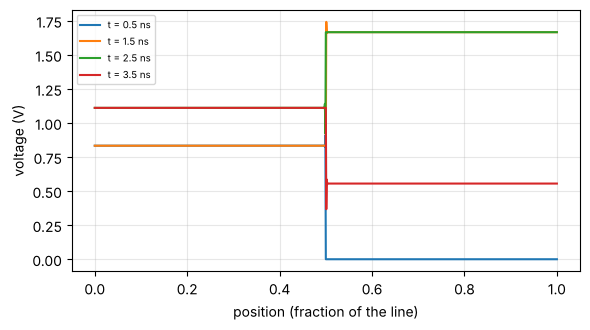

In [2]:
snap_steps = [int(x * 1000) for x in (0.5, 1.5, 2.5, 3.5)]
t, vin, vout, snaps = line_sim([50], [1e-9], 1.0, 10, None, 4e-9, snapshots=snap_steps)
z = np.linspace(0, 1, 1001)
fig, ax = plt.subplots(figsize=(6, 3.4))
for tt, prof in snaps.items():
    ax.plot(z, prof, label=f"t = {tt * 1e9:.1f} ns")
ax.set_xlabel('position (fraction of the line)'); ax.set_ylabel('voltage (V)'); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 2 · Bounce diagram against simulation

Compute the receiver voltage from the bounce-diagram sum $v_L = v^+(1 + \Gamma_L)\sum(\Gamma_S\Gamma_L)^k$ and overlay the simulation.

**Predict first:** for a 100 Ω source on a 50 Ω line into 25 Ω, does the voltage ring or creep?

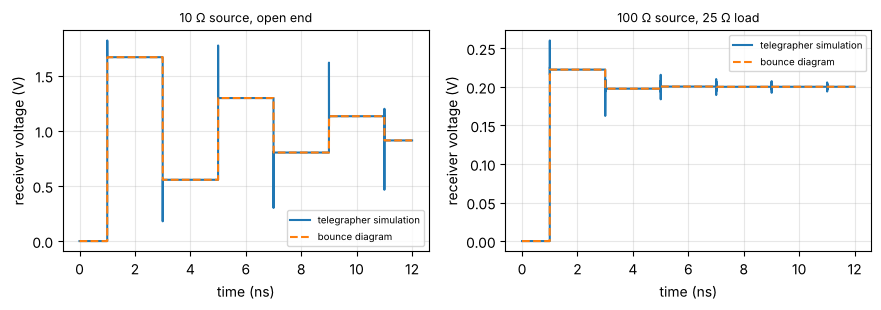

receiver at 1.5, 3.5, 5.5 ns: [1.6667, 0.5556, 1.2963]


In [3]:
def bounce(Vs, Rs, Z0, RL, TD, t):
    vp = Vs * Z0 / (Rs + Z0)
    GS = (Rs - Z0) / (Rs + Z0); GL = 1.0 if RL is None else (RL - Z0) / (RL + Z0)
    v = np.zeros_like(t)
    for k in range(60):
        v += np.where(t >= (2 * k + 1) * TD, vp * (1 + GL) * (GS * GL) ** k, 0.0)
    return v

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (Rs, RL, title) in zip(axes, ((10, None, '10 Ω source, open end'), (100, 25, '100 Ω source, 25 Ω load'))):
    t, vin, vout, _ = line_sim([50], [1e-9], 1.0, Rs, RL, 12e-9)
    ax.plot(t * 1e9, vout, label='telegrapher simulation'); ax.plot(t * 1e9, bounce(1.0, Rs, 50, RL, 1e-9, t), '--', label='bounce diagram')
    ax.set_title(title, fontsize=9); ax.set_xlabel('time (ns)'); ax.set_ylabel('receiver voltage (V)'); ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
t, vin, vout, _ = line_sim([50], [1e-9], 1.0, 10, None, 8e-9)
print('receiver at 1.5, 3.5, 5.5 ns:', [round(float(np.interp(x, t, vout)), 4) for x in (1.5e-9, 3.5e-9, 5.5e-9)])

## Part 3 · When does a line need termination?

Drive an open line through 10 Ω with a 100 ps linear edge, and vary the line's delay from a tenth of the rise time to twice it. Plot the peak overshoot.

**Predict first:** how much overshoot at a delay of one sixth of the rise time? At a delay equal to the rise time?

delay = 0.050 x rise time: overshoot   3.9%
delay = 0.100 x rise time: overshoot   9.1%
delay = 0.167 x rise time: overshoot  17.2%
delay = 0.250 x rise time: overshoot  11.1%
delay = 0.350 x rise time: overshoot  33.3%
delay = 0.500 x rise time: overshoot  66.7%
delay = 0.750 x rise time: overshoot  66.7%
delay = 1.000 x rise time: overshoot  66.7%
delay = 1.500 x rise time: overshoot  66.7%
delay = 2.000 x rise time: overshoot  66.7%


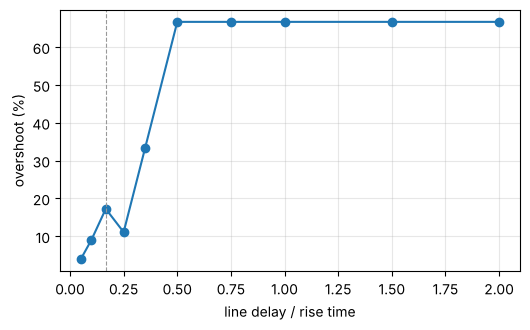

In [4]:
ratios = np.array([0.05, 0.1, 1 / 6, 0.25, 0.35, 0.5, 0.75, 1.0, 1.5, 2.0])
over = []
for r in ratios:
    TD = 100e-12 * r
    t, vin, vout, _ = line_sim([50], [TD], 1.0, 10, None, 20 * max(TD, 100e-12) + 2e-9, cpns=20000, rise=100e-12)
    over.append((vout.max() - 1) * 100)
for r, o in zip(ratios, over):
    print(f"delay = {r:5.3f} x rise time: overshoot {o:5.1f}%")
fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.plot(ratios, over, 'o-'); ax.axvline(1 / 6, color='0.6', lw=0.8, ls='--')
ax.set_xlabel('line delay / rise time'); ax.set_ylabel('overshoot (%)'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 4 · A simulated TDR trace

A matched 1 V TDR step (20 ps edge) looks into a 50 Ω line with a 1 pF via at 0.5 ns, a 45 Ω section from 1.0 to 1.3 ns, and a matched end. Plot the normalized reflection against round-trip time and extract the via's capacitance from the dip's area.

**Predict first:** at what round-trip times do the via and the low-impedance section appear?

via dip area -25.00 ps -> C = 1.000 pF; flat reflection in the 45 ohm section: -0.0526 -> Z = 45.00 ohm


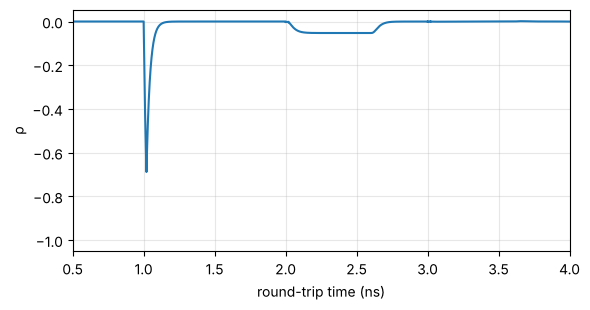

In [5]:
t, vin, vout, _ = line_sim([50, 50, 45, 50], [0.5e-9, 0.5e-9, 0.3e-9, 0.7e-9], 2.0, 50, 50, 5e-9, cpns=5000,
                          rise=20e-12, shunt=(0, 1e-12))
rho = vin - 1.0
dip = (t > 0.8e-9) & (t < 1.6e-9)
area = np.sum(rho[dip]) * (t[1] - t[0])
print(f"via dip area {area * 1e12:.2f} ps -> C = {-2 * area / 50 * 1e12:.3f} pF; flat reflection in the 45 ohm section: "
      f"{np.interp(2.3e-9, t, rho):+.4f} -> Z = {50 * (1 + np.interp(2.3e-9, t, rho)) / (1 - np.interp(2.3e-9, t, rho)):.2f} ohm")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(t * 1e9, rho); ax.set_xlabel('round-trip time (ns)'); ax.set_ylabel('ρ'); ax.set_xlim(0.5, 4); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## What to notice

- For the first round trip the source sees only $Z_0$; the receiver's waveform is a sum of delayed copies, exactly the bounce diagram.
- Overshoot is under 10% for delays below a tenth of the rise time, already 17% at a sixth, and the full bounce-diagram value (67% here) once the delay reaches half the rise time. With a linear edge the curve is not monotonic in between, because successive reflections partly cancel; the critical-length guideline marks where reflections stop being negligible.
- On a TDR, a via shows as a dip whose area gives its capacitance; a section of different impedance shows as a flat shelf whose height gives its impedance and whose width gives its length.